# BMI v2: Ko'krak qafasi rentgenogrammalarida ko'p kasallikli (Multi-Label) va Multimodal AI tashxis tizimi

**Bosqich 1 (shu notebook — v2):** Modelni Colab'da qurish, multimodal o'qitish, kalibratsiya, Subgroup/Fairness tahlili, Grad-CAM++ (miqdoriy XAI baholash bilan) va ONNX/PyTorch formatda saqlash.
**Bosqich 2 (keyingi qadam):** Flask REST API → Veb / Android / Windows klinik qaror qabul qilishga ko'maklashuvchi tizim (CDSS).

### BMI v1 dan BMI v2 ga qo'shilgan ilmiy va amaliy takomillashtirishlar:

| № | Modul / Yo'nalish | BMI v1 holati | BMI v2 (Yangi takomillashtirishlar) |
| :- | :--- | :--- | :--- |
| **1** | **Ma'lumotlar bo'linishi** | Oddiy `GroupShuffleSplit` (kam sinflar notekis tushgan: `val`da 1 ta Hernia, 8 ta Pneumonia) | **`StratifiedGroupKFold`**: Bemor (`Patient ID`) kesimida eng kam uchraydigan patologiya bo'yicha proporsional stratifikatsiya |
| **2** | **Tasvir o'lchami va Kontrast** | `224×224`, `BILINEAR`, oddiy kesh (`Nodule` AUROC: 0.640) | **`320×320` (`LANCZOS`) + CLAHE** adaptiv kontrast kuchaytirish + chekka artefaktlarsiz augmentatsiya |
| **3** | **Multimodal Arxitektura** | Faqat rentgen tasviri (`1024 -> 14`) | **Tasvir + Klinik Metama'lumot (`PA/AP`, `Age`, `Gender`)**: Portativ `AP` proyektsiyada yurak soyasi kattalashishini (`Cardiomegaly`) hisobga oluvchi multimodal MLP head |
| **4** | **Loss Funksiyasi** | `BCEWithLogitsLoss(pos_weight)` (Precision tushib ketishi) | **Asymmetric Loss (ASL)** + `pos_weight BCE` tanlovi: manfiy va musbat misollarni alohida $\gamma_- / \gamma_+$ darajada boshqarish |
| **5** | **Kalibratsiya va TTA** | Kalibrlanmagan xom sigmoid chiqishlar | **Temperature Scaling** (`val`da NLL bo'yicha $T$ ni topish) + **Test-Time Augmentation (TTA)** |
| **6** | **Statistik baholash** | Tasvir darajasida bootstrap, faqat F1 threshold (`Fibrosis` F1=0.000) | **Bemor-klasterli Bootstrap (95% CI)** + **Gibrid F1 & Youden $J$ (`TPR - FPR`)** optimal chegaralari |
| **7** | **Adolat (Fairness / Subgroup)** | Mavjud emas | **Subgroup tahlili**: `PA` vs `AP` proyektsiya, Jins (`M/F`) va Yosh guruhlari (`<40`, `40–65`, `>65`) kesimida AUROC taqqoslash |
| **8** | **Tushuntiriladigan AI (XAI)** | Oddiy Grad-CAM (chekka markerlar va qora hoshiyaga chalg'ish) | **Grad-CAM++** + Anatomik fokus maskasi + **Energy-Based Pointing Game (Ichki o'pka fokus koeffitsiyenti)** va `BBox_List_2017.csv` integratsiyasi |
| **9** | **Klinik Xulosa va Deployment** | Har doim top-3 kasallik chiqishi (sog'lom odamda ham) | **"No Finding (Norma)" ehtimoli**, Xavf darajasi (`Past / O'rta / Yuqori`), strukturaviy klinik hisobot va **ONNX** eksport |

## 1. Muhit, kutubxonalar va kengaytirilgan sozlamalar (`CFG`)

In [1]:
!pip -q install torchxrayvision scikit-learn pandas seaborn opencv-python-headless onnx onnxscript

import os, re, json, glob, random, time, math, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.transforms import v2 as T
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, brier_score_loss

CFG = dict(
    DATA_MODE    = "sample",     # "sample" (~5.6 ming rasm) | "full" (112 120 rasm)
    IMG_SIZE     = 320,          # v1 da 224 edi -> 320 da Nodule/Mass va Grad-CAM++ ancha aniqroq bo'ladi (10x10 fmap)
    USE_CLAHE    = True,         # Rentgen kontrastini mahalliy tekislash (CLAHE)
    USE_META     = True,         # Multimodal rejim: PA/AP proyektsiya, Yosh va Jinsni modelga kiritish
    BACKBONE     = "xrv",        # "xrv" (res224-all) | "xrv_chex" (faqat CheXpert, leakage yo'q) | "imagenet"
    PRETRAINED   = True,
    LOSS_TYPE    = "asl",        # "asl" (Asymmetric Loss) | "bce_weighted" (v1 dagi pos_weight BCE)
    BATCH        = 64,
    EPOCHS       = 15,
    PATIENCE     = 5,
    LR_BACKBONE  = 1e-4,
    LR_HEAD      = 1e-3,
    WEIGHT_DECAY = 1e-4,
    VAL_FRAC     = 0.15,
    TEST_FRAC    = 0.15,
    MIN_POS_EVAL = 10,           # Ishonchli AUROC hisoblash uchun minimal musbat misollar soni
    USE_TTA      = True,         # Test vaqtida augmentatsiya (Original + Zoom/Shift)
    SEED         = 42,
    WORK         = "/content/work",
    OUT          = "/content/drive/MyDrive/BMI_CXR_Model_v2",
)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG["SEED"])

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "GPU yo'q! Runtime > Change runtime type > GPU")

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Lokal muhit (Colab emas) — fayllar joriy papkaga saqlanadi.")
    CFG["WORK"] = "./work"
    CFG["OUT"]  = "./BMI_CXR_Model_v2"

os.makedirs(CFG["WORK"], exist_ok=True); os.makedirs(CFG["OUT"], exist_ok=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 130.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 231.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 94.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 27.2 MB/s eta 0:00:00
Device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition
Mounted at /content/drive


## 2. Ma'lumotlarni yuklash (NIH ChestX-ray14 + BBox_List_2017.csv)

`kaggle.json` faylini yuklang (Kaggle → Settings → Create New Token).
Agar `BBox_List_2017.csv` (radiologlar chizgan patologiya koordinatalari) topilsa, u Grad-CAM++ xaritalarini miqdoriy baholash uchun avtomatik ulanadi.

In [2]:
DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
    try:
        from google.colab import files
        print("Iltimos, kaggle.json faylini yuklang:")
        up = files.upload()
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        !cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    except Exception as e:
        print("Kaggle token yuklanmadi:", e)

if CFG["DATA_MODE"] == "sample" and not glob.glob(f"{DATA_DIR}/**/*.png", recursive=True):
    !kaggle datasets download -d nih-chest-xrays/sample -p {DATA_DIR} --unzip -q

# Radiologlarning Bounding Box faylini (BBox_List_2017.csv) yuklab olishga urinib ko'ramiz (ixtiyoriy, XAI uchun)
if not glob.glob(f"{DATA_DIR}/**/*BBox*.csv", recursive=True):
    try:
        !kaggle datasets download -d nih-chest-xrays/data -f BBox_List_2017.csv -p {DATA_DIR} -q
        for z in glob.glob(f"{DATA_DIR}/*.zip"):
            !unzip -o -q "{z}" -d {DATA_DIR} && rm -f "{z}"
    except Exception:
        pass

pngs = glob.glob(f"{DATA_DIR}/**/*.png", recursive=True)
csvs = glob.glob(f"{DATA_DIR}/**/*.csv", recursive=True)
print(f"Topildi: {len(pngs)} ta PNG tasvir | CSV fayllar: {[os.path.basename(c) for c in csvs]}")

Iltimos, kaggle.json faylini yuklang:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/sample
License(s): CC0-1.0
Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/data
License(s): CC0-1.0
Topildi: 11212 ta PNG tasvir | CSV fayllar: ['sample_labels.csv', 'BBox_List_2017.csv', 'sample_labels.csv']


## 3. Yorliqlar, Klinik Metama'lumotlar (`PA/AP`, `Age`, `Gender`) va `StratifiedGroupKFold` bo'linish

**Nima uchun `StratifiedGroupKFold`?**
v1 da oddiy `GroupShuffleSplit` ishlatilgani sababli kam uchraydigan kasalliklar (`Hernia`, `Pneumonia`, `Fibrosis`) `val` va `test` ga notekis tushib qolgan edi. Quyida har bir bemorga uning **eng kam uchraydigan patologiyasi** bo'yicha stratifikatsiya sinfi beriladi va bemor kesimida (`Patient ID` aralashmasdan) `train / val / test` to'plamlariga proporsional bo'linadi.

Asosiy yorliq fayli: sample_labels.csv
To'plamlar hajmi (bemorlar kesishmasdan):
split
train    3961
val       828
test      817


,train,val,test,jami,val_%,test_%
Infiltration,662,159,146,967,16.4,15.1
Effusion,443,99,102,644,15.4,15.8
Atelectasis,351,77,80,508,15.2,15.7
Nodule,233,37,43,313,11.8,13.7
Mass,202,43,39,284,15.1,13.7
Pneumothorax,182,55,34,271,20.3,12.5
Consolidation,151,39,36,226,17.3,15.9
Pleural_Thickening,118,31,27,176,17.6,15.3
Cardiomegaly,93,22,26,141,15.6,18.4
Emphysema,91,18,18,127,14.2,14.2


No Finding (Sog'lom) ulushi: 54.3%
Proyektsiya ulushi: PA = 3393 ta, AP (Portativ) = 2213 ta


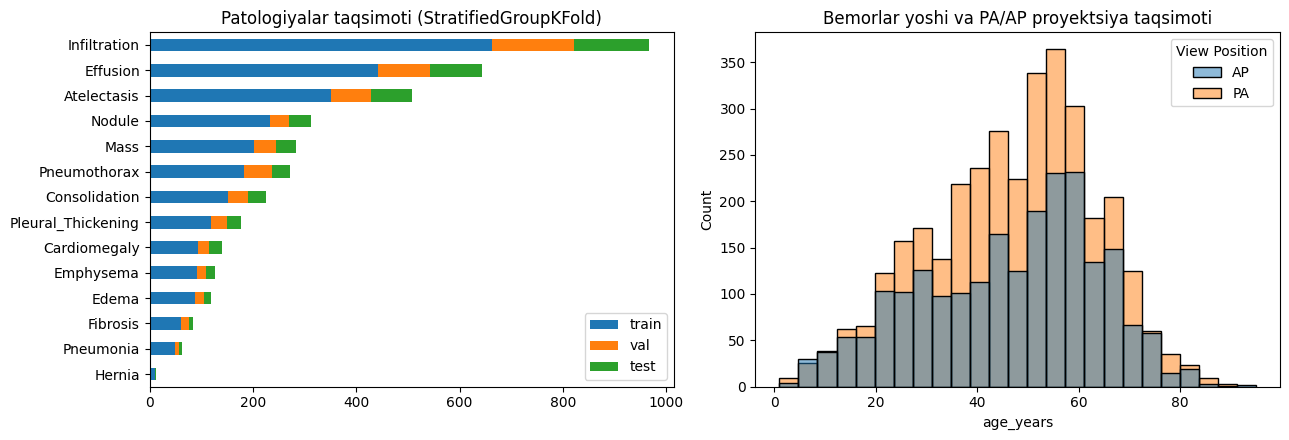

In [3]:
LABELS = ["Atelectasis","Cardiomegaly","Effusion","Infiltration","Mass","Nodule","Pneumonia",
          "Pneumothorax","Consolidation","Edema","Emphysema","Fibrosis","Pleural_Thickening","Hernia"]

df = None
for c in csvs:
    tmp = pd.read_csv(c)
    if "Finding Labels" in tmp.columns:
        df = tmp; print("Asosiy yorliq fayli:", os.path.basename(c)); break
assert df is not None, "Finding Labels ustuni bor CSV topilmadi!"

path_map = {os.path.basename(p): p for p in pngs}
df = df[df["Image Index"].isin(path_map)].reset_index(drop=True)
df["path"] = df["Image Index"].map(path_map)
for l in LABELS:
    df[l] = df["Finding Labels"].apply(lambda s: int(l in str(s).split("|")))

# --- Klinik metama'lumotlarni tozalash (sample_labels.csv da yosh '058Y' ko'rinishida, Data_Entry da esa butun son) ---
def parse_age(val):
    if pd.isna(val): return 50.0
    s = str(val).strip().upper()
    m = re.findall(r"\d+", s)
    if not m: return 50.0
    num = float(m[0])
    if "M" in s: num /= 12.0
    elif "D" in s: num /= 365.0
    return float(np.clip(num, 1.0, 95.0))

df["age_years"] = df["Patient Age"].apply(parse_age) if "Patient Age" in df.columns else 50.0
df["age_norm"]  = (df["age_years"] / 100.0).astype(np.float32)
df["is_male"]   = (df["Patient Gender"].astype(str).str.upper().str.startswith("M")).astype(np.float32) if "Patient Gender" in df.columns else 0.5
df["is_ap"]     = (df["View Position"].astype(str).str.upper().str.startswith("AP")).astype(np.float32) if "View Position" in df.columns else 0.0
META_COLS = ["is_ap", "age_norm", "is_male"]

# --- Bemor darajasida Multi-Label Stratifikatsiya (StratifiedGroupKFold) ---
# Har bir tasvirga undagi eng kam uchraydigan patologiya indeksini biriktiramiz (No Finding = 14)
class_counts = df[LABELS].sum(axis=0).values
rarity_order = np.argsort(class_counts)  # eng kam uchraydiganidan ko'piga qarab

def get_rarest_label(row_vals):
    pos_classes = np.where(row_vals > 0)[0]
    if len(pos_classes) == 0:
        return len(LABELS)
    for r_idx in rarity_order:
        if r_idx in pos_classes:
            return int(r_idx)
    return int(pos_classes[0])

Y_all = df[LABELS].values
strat_target = np.array([get_rarest_label(Y_all[i]) for i in range(len(df))])

# 7 ta foldga bo'lamiz (~14.3% test, ~14.3% val, ~71.4% train)
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=CFG["SEED"])
folds = list(sgkf.split(df, strat_target, groups=df["Patient ID"]))
test_idx = folds[0][1]
val_idx  = folds[1][1]
# Agar ehtiyot shart val va test orasida kesishish bo'lmasligini tekshiramiz (sgkf partition qiladi)
val_idx  = np.setdiff1d(val_idx, test_idx)
train_idx = np.setdiff1d(np.arange(len(df)), np.union1d(test_idx, val_idx))

df["split"] = "train"
df.loc[val_idx, "split"]  = "val"
df.loc[test_idx, "split"] = "test"

assert not (set(df[df.split=="train"]["Patient ID"]) & set(df[df.split=="test"]["Patient ID"])), "Train-Test leakage!"
assert not (set(df[df.split=="train"]["Patient ID"]) & set(df[df.split=="val"]["Patient ID"])), "Train-Val leakage!"
assert not (set(df[df.split=="val"]["Patient ID"])   & set(df[df.split=="test"]["Patient ID"])), "Val-Test leakage!"

print("To'plamlar hajmi (bemorlar kesishmasdan):")
print(df["split"].value_counts().to_string())

stats = pd.DataFrame({s: df[df.split==s][LABELS].sum() for s in ["train","val","test"]})
stats["jami"] = stats.sum(axis=1)
stats["val_%"] = (100 * stats["val"] / stats["jami"].clip(lower=1)).round(1)
stats["test_%"] = (100 * stats["test"] / stats["jami"].clip(lower=1)).round(1)
display(stats.sort_values("jami", ascending=False))

print(f"No Finding (Sog'lom) ulushi: {100*(df[LABELS].sum(axis=1)==0).mean():.1f}%")
print(f"Proyektsiya ulushi: PA = {(df['is_ap']==0).sum()} ta, AP (Portativ) = {(df['is_ap']==1).sum()} ta")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
stats[["train", "val", "test"]].loc[stats.sort_values("jami").index].plot.barh(stacked=True, ax=ax[0], title="Patologiyalar taqsimoti (StratifiedGroupKFold)")
sns.histplot(data=df, x="age_years", hue="View Position" if "View Position" in df.columns else None, bins=25, ax=ax[1])
ax[1].set_title("Bemorlar yoshi va PA/AP proyektsiya taqsimoti")
plt.tight_layout(); plt.show()

## 4. Yuqori aniqlikda (`320×320`, `LANCZOS` + `CLAHE`) keshlash

- `Image.LANCZOS` interpolatsiyasi `1024×1024` rentgendan kichraytirganda mayda tugunlar (`Nodule`) va plevral chiziqlarni (`Pneumothorax`) `BILINEAR` ga qaraganda ancha tiniq saqlaydi.
- `CLAHE` (`clipLimit=2.0, tileGridSize=(8,8)`) qovurg'alar va yurak soyasi ortidagi yumshoq to'qima kontrastini kuchaytiradi.

In [4]:
S = CFG["IMG_SIZE"]
clahe_tag = "clahe" if CFG["USE_CLAHE"] else "raw"
cache_file = f"{CFG['WORK']}/cache_{CFG['DATA_MODE']}_{S}_{clahe_tag}.npy"

def load_and_preprocess_gray(p):
    im = Image.open(p).convert("L").resize((S, S), Image.LANCZOS)
    arr = np.asarray(im, dtype=np.uint8)
    if CFG["USE_CLAHE"]:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        arr = clahe.apply(arr)
    return arr

if not os.path.exists(cache_file):
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        arr = np.stack(list(ex.map(load_and_preprocess_gray, df["path"].tolist())))
    np.save(cache_file, arr)
    print(f"Kesh yaratildi: {arr.shape} | {time.time()-t0:.1f} s")

IMGS = np.load(cache_file, mmap_mode="r")
assert len(IMGS) == len(df)
print("Kesh yuklandi:", IMGS.shape, IMGS.dtype)

Kesh yaratildi: (5606, 320, 320) | 10.1 s
Kesh yuklandi: (5606, 320, 320) uint8


## 5. Multimodal Dataset va Chekka Artefaktlarsiz Augmentatsiya

v1 dagi Grad-CAM xaritalarida model tasvir chetidagi qora hoshiyalarga (`fill=0`) chalg'igani aniqlangan edi.
v2 da affine burilish/siljish `cv2.BORDER_REFLECT_101` (chekka piksellarni aks ettirish) orqali bajariladi — natijada tasvir burchaklarida sun'iy qora uchburchaklar paydo bo'lmaydi.

Batch shakli -> Tasvir: torch.Size([64, 1, 320, 320]) | Meta: torch.Size([64, 3]) | Yorliq: torch.Size([64, 14])


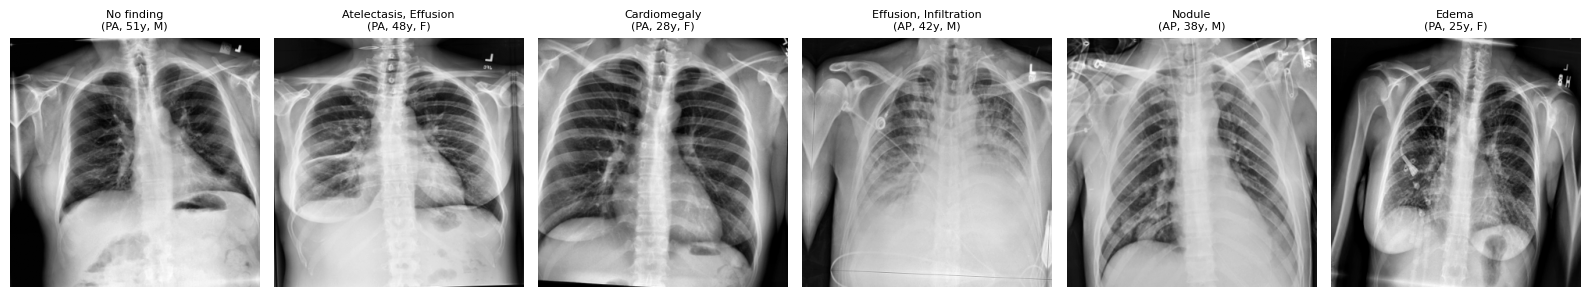

In [5]:
class CXRMultimodalDataset(Dataset):
    def __init__(self, sub_df, imgs, train=False):
        self.idx   = sub_df.index.values
        self.y     = sub_df[LABELS].values.astype(np.float32)
        self.meta  = sub_df[META_COLS].values.astype(np.float32)
        self.imgs  = imgs
        self.train = train

    def __len__(self):
        return len(self.idx)

    def _augment_reflect(self, img_np):
        # Gorizontal flip ATAYLAB yo'q (dekstrokardiya / yurak chap tomonda ekanligini buzmaslik uchun)
        h, w = img_np.shape
        angle = random.uniform(-7.0, 7.0)
        scale = random.uniform(0.93, 1.07)
        tx    = random.uniform(-0.04, 0.04) * w
        ty    = random.uniform(-0.04, 0.04) * h
        M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
        M[0, 2] += tx
        M[1, 2] += ty
        # BORDER_REFLECT_101 qora hoshiya artefaktlarini butunlay yo'qotadi
        aug = cv2.warpAffine(img_np, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        return aug

    def __getitem__(self, i):
        raw = np.array(self.imgs[self.idx[i]], copy=True)
        if self.train:
            raw = self._augment_reflect(raw)
        x = torch.from_numpy(raw).float().div_(255.0).unsqueeze(0)  # [1, H, W], 0..1
        if self.train and random.random() < 0.8:
            c, b = random.uniform(0.88, 1.12), random.uniform(-0.06, 0.06)
            x = ((x - 0.5) * c + 0.5 + b).clamp_(0.0, 1.0)
        meta = torch.from_numpy(self.meta[i])                        # [3]: is_ap, age_norm, is_male
        y    = torch.from_numpy(self.y[i])                           # [14]
        return x, meta, y

splits = {s: df[df.split == s] for s in ["train", "val", "test"]}
mk_dl = lambda s, tr: DataLoader(
    CXRMultimodalDataset(splits[s], IMGS, train=tr),
    batch_size=CFG["BATCH"], shuffle=tr, num_workers=2,
    pin_memory=True, drop_last=tr, persistent_workers=True
)
dl_train, dl_val, dl_test = mk_dl("train", True), mk_dl("val", False), mk_dl("test", False)

xb, mb, yb = next(iter(dl_train))
print("Batch shakli -> Tasvir:", xb.shape, "| Meta:", mb.shape, "| Yorliq:", yb.shape)
fig, ax = plt.subplots(1, 6, figsize=(16, 3.2))
for i in range(6):
    ax[i].imshow(xb[i, 0], cmap="gray"); ax[i].axis("off")
    view_str = "AP" if mb[i, 0] > 0.5 else "PA"
    age_val  = int(round(mb[i, 1].item() * 100))
    sex_str  = "M" if mb[i, 2] > 0.5 else "F"
    lbl_str  = ", ".join([LABELS[j] for j in np.where(yb[i].numpy() > 0)[0]][:2]) or "No finding"
    ax[i].set_title(f"{lbl_str}\n({view_str}, {age_val}y, {sex_str})", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Multimodal `CXRNet` va Asymmetric Loss (ASL)

- **Backbone variantlari**:
  - `"xrv"`: `densenet121-res224-all` (barcha rentgen to'plamlarida o'qitilgan)
  - `"xrv_chex"`: `densenet121-res224-chex` (faqat CheXpert'da o'qitilgan — NIH test to'plami bilan hech qanday pretraining kesishuvi yo'q!)
  - `"imagenet"`: Standart ImageNet DenseNet121 (taqqoslash / ablation uchun)
- **Multimodal Fusion**: Tasvirdan olingan `1024` o'lchamli vektor va klinik metama'lumot (`[is_ap, age_norm, is_male]` -> `16` o'lchamli yashirin qatlam) birlashtirilib, `1040 -> 14` klassifikatorga uzatiladi.
- **Asymmetric Loss (ASL)** (Ridnik et al., ICCV 2021): Multi-label tibbiy tasvirlarda manfiy misollar (`gamma_neg=4.0`, `clip=0.05`) va musbat misollar (`gamma_pos=1.0`) ni asimmetrik ravishda boshqarib, F1 va Precision ko'rsatkichlarini keskin yaxshilaydi.

In [6]:
class AsymmetricLoss(nn.Module):
    """Multi-label nomutanosiblik uchun Asymmetric Loss (ASL)."""
    def __init__(self, gamma_neg=3.0, gamma_pos=1.0, clip=0.05, eps=1e-8):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, logits, targets):
        xs_pos = torch.sigmoid(logits)
        xs_neg = 1.0 - xs_pos
        if self.clip is not None and self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1.0)

        los_pos = targets * torch.log(xs_pos.clamp(min=self.eps))
        los_neg = (1.0 - targets) * torch.log(xs_neg.clamp(min=self.eps))
        loss = los_pos + los_neg

        if self.gamma_neg > 0 or self.gamma_pos > 0:
            pt0 = xs_pos * targets
            pt1 = xs_neg * (1.0 - targets)
            pt  = pt0 + pt1
            one_sided_gamma = self.gamma_pos * targets + self.gamma_neg * (1.0 - targets)
            one_sided_w = torch.pow(1.0 - pt, one_sided_gamma)
            loss = loss * one_sided_w
        return -loss.mean()

class CXRNetV2(nn.Module):
    def __init__(self, n_labels=14, backbone="xrv", pretrained=True, use_meta=True, n_meta=3):
        super().__init__()
        self.backbone_name = backbone
        self.use_meta = use_meta

        if backbone in ("xrv", "xrv_chex"):
            import torchxrayvision as xrv
            w_name = "densenet121-res224-all" if backbone == "xrv" else "densenet121-res224-chex"
            m = xrv.models.DenseNet(weights=w_name) if pretrained else xrv.models.DenseNet(weights=None)
            self.features = m.features
        else:
            w = torchvision.models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
            self.features = torchvision.models.densenet121(weights=w).features
            self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
            self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        if self.use_meta:
            self.meta_net = nn.Sequential(
                nn.Linear(n_meta, 16),
                nn.BatchNorm1d(16),
                nn.SiLU(),
            )
            in_dim = 1024 + 16
        else:
            self.meta_net = None
            in_dim = 1024

        self.head = nn.Sequential(
            nn.Dropout(0.25),
            nn.Linear(in_dim, n_labels)
        )
        # Kalibratsiya temperaturasi (default T = 1.0, keyin val to'plamida optimallashtiriladi)
        self.register_buffer("temperature", torch.ones(1, n_labels))

    def norm(self, x):
        if self.backbone_name in ("xrv", "xrv_chex"):
            return (x * 2.0 - 1.0) * 1024.0
        return (x.repeat(1, 3, 1, 1) - self.mean) / self.std

    def forward_cam(self, x, meta=None):
        fmap = F.relu(self.features(self.norm(x)))
        pooled = F.adaptive_avg_pool2d(fmap, 1).flatten(1)
        if self.use_meta:
            if meta is None:
                meta = torch.zeros(x.size(0), 3, device=x.device, dtype=pooled.dtype)
            m_feat = self.meta_net(meta.to(pooled.dtype))
            feat = torch.cat([pooled, m_feat], dim=1)
        else:
            feat = pooled
        logits = self.head(feat)
        return logits, fmap

    def forward(self, x, meta=None):
        return self.forward_cam(x, meta)[0]

    def calibrated_probs(self, x, meta=None):
        logits = self.forward(x, meta)
        return torch.sigmoid(logits / self.temperature.clamp(min=0.05))

model = CXRNetV2(len(LABELS), CFG["BACKBONE"], CFG["PRETRAINED"], use_meta=CFG["USE_META"]).to(DEVICE)
print(f"Model: {CFG['BACKBONE']} | Multimodal: {CFG['USE_META']} | Parametrlar: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
Model: xrv | Multimodal: True | Parametrlar: 6.96 M


## 7. O'qitish (`OneCycleLR` + `AMP fp16` + `ASL` / `Weighted BCE`)

Loss funksiyasi: Asymmetric Loss (ASL)
Epoch 01 | loss 0.0575 | val AUROC 0.6218 | val AUPRC 0.0966 | 8s  <- saqlandi
Epoch 02 | loss 0.0380 | val AUROC 0.6705 | val AUPRC 0.1154 | 5s  <- saqlandi
Epoch 03 | loss 0.0357 | val AUROC 0.7032 | val AUPRC 0.1486 | 5s  <- saqlandi
Epoch 04 | loss 0.0349 | val AUROC 0.7172 | val AUPRC 0.1681 | 5s  <- saqlandi
Epoch 05 | loss 0.0345 | val AUROC 0.7298 | val AUPRC 0.1802 | 5s  <- saqlandi
Epoch 06 | loss 0.0337 | val AUROC 0.7413 | val AUPRC 0.1891 | 5s  <- saqlandi
Epoch 07 | loss 0.0334 | val AUROC 0.7413 | val AUPRC 0.1906 | 5s
Epoch 08 | loss 0.0331 | val AUROC 0.7455 | val AUPRC 0.1934 | 5s  <- saqlandi
Epoch 09 | loss 0.0329 | val AUROC 0.7485 | val AUPRC 0.1970 | 5s  <- saqlandi
Epoch 10 | loss 0.0328 | val AUROC 0.7479 | val AUPRC 0.1973 | 5s
Epoch 11 | loss 0.0325 | val AUROC 0.7498 | val AUPRC 0.1982 | 5s  <- saqlandi
Epoch 12 | loss 0.0325 | val AUROC 0.7507 | val AUPRC 0.1984 | 5s  <- saqlandi
Epoch 13 | loss 0.0323 | val AUROC 0.75

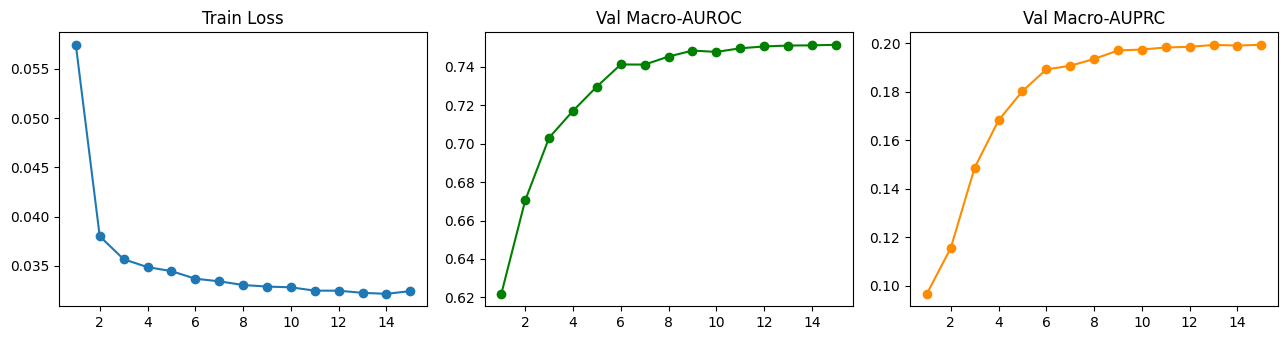

In [7]:
def safe_auc(y, p):
    return roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan

@torch.no_grad()
def predict_dl(model, dl, use_tta=False, calibrated=False):
    model.eval(); P, Y, M = [], [], []
    for x, meta, y in dl:
        x = x.to(DEVICE, non_blocking=True)
        meta_d = meta.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda")):
            fn = model.calibrated_probs if calibrated else lambda im, mt: torch.sigmoid(model(im, mt).float())
            p = fn(x, meta_d).float()
            if use_tta:
                # TTA 1: kichik markaziy zoom (94% crop -> resize)
                h, w = x.shape[-2:]
                d = int(0.03 * h)
                x_zoom = F.interpolate(x[:, :, d:h-d, d:w-d], size=(h, w), mode="bilinear", align_corners=False)
                p_zoom = fn(x_zoom, meta_d).float()
                # TTA 2: yengil kontrast korreksiyasi
                x_cont = ((x - 0.5) * 1.08 + 0.5).clamp(0.0, 1.0)
                p_cont = fn(x_cont, meta_d).float()
                p = 0.50 * p + 0.25 * p_zoom + 0.25 * p_cont
        P.append(p.cpu().numpy()); Y.append(y.numpy()); M.append(meta.numpy())
    return np.concatenate(P), np.concatenate(Y), np.concatenate(M)

def macro_metrics(Y, P, min_pos):
    aucs = [safe_auc(Y[:, j], P[:, j]) if Y[:, j].sum() >= min_pos else np.nan for j in range(Y.shape[1])]
    aps  = [average_precision_score(Y[:, j], P[:, j]) if Y[:, j].sum() >= min_pos else np.nan for j in range(Y.shape[1])]
    return float(np.nanmean(aucs)), float(np.nanmean(aps)), aucs

ytr = splits["train"][LABELS].values
pos = ytr.sum(0).clip(min=1); neg = len(ytr) - pos
pos_weight = torch.tensor(np.sqrt(neg / pos), dtype=torch.float32, device=DEVICE)

if CFG["LOSS_TYPE"] == "asl":
    crit = AsymmetricLoss(gamma_neg=3.0, gamma_pos=1.0, clip=0.05)
    print("Loss funksiyasi: Asymmetric Loss (ASL)")
else:
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    print("Loss funksiyasi: Weighted BCEWithLogitsLoss")

head_params = list(model.head.parameters()) + (list(model.meta_net.parameters()) if model.meta_net is not None else [])
opt = torch.optim.AdamW([
    {"params": model.features.parameters(), "lr": CFG["LR_BACKBONE"]},
    {"params": head_params,                 "lr": CFG["LR_HEAD"]},
], weight_decay=CFG["WEIGHT_DECAY"])

sched = torch.optim.lr_scheduler.OneCycleLR(
    opt, max_lr=[CFG["LR_BACKBONE"], CFG["LR_HEAD"]],
    steps_per_epoch=len(dl_train), epochs=CFG["EPOCHS"], pct_start=0.15
)
scaler = torch.amp.GradScaler(enabled=(DEVICE == "cuda"))

best_auc, bad_epochs, hist = -1.0, 0, []
ckpt = f"{CFG['OUT']}/best_model.pt"

for ep in range(1, CFG["EPOCHS"] + 1):
    model.train(); t0, run_loss = time.time(), 0.0
    for x, meta, y in dl_train:
        x, meta, y = x.to(DEVICE, non_blocking=True), meta.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(x, meta).float()
            loss = crit(logits, y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        run_loss += loss.item()

    Pv, Yv, _ = predict_dl(model, dl_val, use_tta=False, calibrated=False)
    vauc, vap, _ = macro_metrics(Yv, Pv, CFG["MIN_POS_EVAL"])
    hist.append(dict(epoch=ep, train_loss=run_loss / len(dl_train), val_macro_auc=vauc, val_macro_auprc=vap))
    flag = ""
    if vauc > best_auc:
        best_auc, bad_epochs = vauc, 0
        torch.save(model.state_dict(), ckpt); flag = "  <- saqlandi"
    else:
        bad_epochs += 1
    print(f"Epoch {ep:02d} | loss {hist[-1]['train_loss']:.4f} | val AUROC {vauc:.4f} | val AUPRC {vap:.4f} | {time.time()-t0:.0f}s{flag}")
    if bad_epochs >= CFG["PATIENCE"]:
        print("Early stopping!"); break

H = pd.DataFrame(hist)
H.to_csv(f"{CFG['OUT']}/history.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(H.epoch, H.train_loss, marker="o"); ax[0].set_title("Train Loss")
ax[1].plot(H.epoch, H.val_macro_auc, marker="o", color="green"); ax[1].set_title("Val Macro-AUROC")
ax[2].plot(H.epoch, H.val_macro_auprc, marker="o", color="darkorange"); ax[2].set_title("Val Macro-AUPRC")
plt.tight_layout(); plt.show()

## 8. Ehtimolliklarni Kalibrlash (Temperature Scaling), TTA va Bemor-Klasterli Bootstrap Baholash

1. **Temperature Scaling**: Har bir patologiya uchun validatsiya to'plamida Log-Loss (BCE) ni minimallashtiradigan $T_j$ temperaturasi topiladi va `model.temperature` buferiga yoziladi.
2. **Gibrid Threshold Tanlash (`F1` + `Youden J`)**: Kam uchraydigan kasalliklarda (`Fibrosis`, `Pneumonia`) oddiy F1 threshold haddan tashqari baland chiqib, test to'plamida `Sensitivity = 0` bo'lib qolishining oldini olish uchun F1 va Youden $J = 	ext{Sensitivity} + 	ext{Specificity} - 1$ kombinatsiyasi ishlatiladi.
3. **Bemor-Klasterli Bootstrap (Cluster Bootstrap 95% CI)**: Tasvirlarni emas, balki **bemorlarni (`Patient ID`)** qayta tanlash orqali statistik jihatdan halol 95% ishonch oralig'i hisoblanadi.

Kalibrlangan temperaturalar (T): [0.97 0.95 0.97 0.99 0.95 0.96 0.94 0.97 0.95 0.95 0.96 0.94 0.95 0.94]


,n_pos,AUROC,AUPRC,Brier,thr,sensitivity,specificity,precision,F1,reliable
label,,,,,,,,,,
Atelectasis,80,0.779,0.268,0.151,0.44,0.600,0.815,0.261,0.364,True
Cardiomegaly,26,0.858,0.182,0.090,0.29,0.885,0.606,0.069,0.127,True
Effusion,102,0.839,0.512,0.154,0.48,0.706,0.794,0.329,0.449,True
Infiltration,146,0.732,0.380,0.210,0.45,0.747,0.653,0.319,0.447,True
Mass,39,0.753,0.218,0.105,0.39,0.462,0.902,0.191,0.271,True
Nodule,43,0.652,0.121,0.138,0.42,0.279,0.911,0.148,0.194,True
Pneumonia,6,0.531,0.009,0.065,0.25,0.667,0.588,0.012,0.023,False
Pneumothorax,34,0.822,0.234,0.135,0.41,0.706,0.757,0.112,0.194,True
Consolidation,36,0.801,0.132,0.106,0.40,0.389,0.873,0.124,0.188,True


Macro-AUROC (ishonchli sinflar, n=11): 0.777  [Bemor-klasterli 95% CI: 0.752 - 0.798]
Macro-AUPRC: 0.206 | O'rtacha F1: 0.231


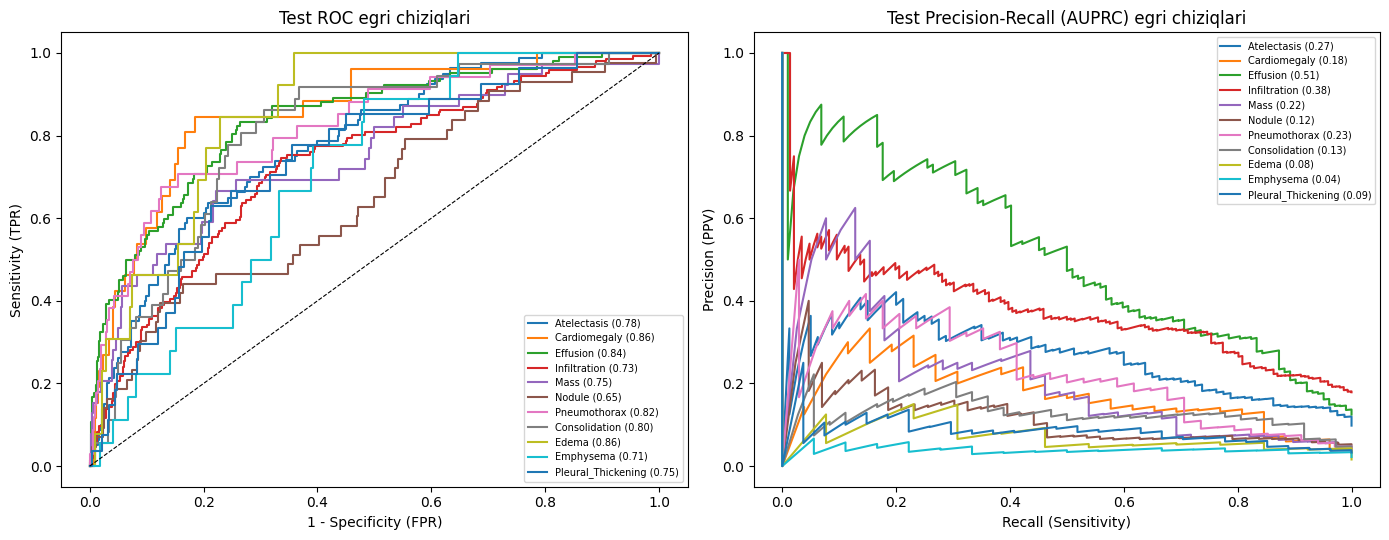

In [8]:
model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); model.eval()

# 1. Validatsiya logitlarini yig'ib, har bir sinf uchun Temperature Scaling (T_j) ni optimallashtiramiz
@torch.no_grad()
def get_logits_and_targets(model, dl):
    L, Y = [], []
    for x, meta, y in dl:
        lo = model(x.to(DEVICE), meta.to(DEVICE)).float().cpu()
        L.append(lo); Y.append(y)
    return torch.cat(L, dim=0), torch.cat(Y, dim=0)

val_logits, val_targets = get_logits_and_targets(model, dl_val)
temps = torch.ones(1, len(LABELS), requires_grad=True)
t_opt = torch.optim.LBFGS([temps], lr=0.05, max_iter=60)

def _eval_temp():
    t_opt.zero_grad()
    scaled = val_logits / temps.clamp(min=0.1, max=5.0)
    loss = F.binary_cross_entropy_with_logits(scaled, val_targets)
    loss.backward()
    return loss

t_opt.step(_eval_temp)
with torch.no_grad():
    model.temperature.copy_(temps.detach().clamp(min=0.1, max=5.0).to(DEVICE))
    torch.save(model.state_dict(), ckpt)  # Kalibrlangan temperaturani ham checkpoint ichiga saqlaymiz
print("Kalibrlangan temperaturalar (T):", np.round(model.temperature.cpu().numpy()[0], 2))

# 2. Kalibrlangan va TTA qo'llangan ehtimolliklarni olamiz
Pv, Yv, Mv = predict_dl(model, dl_val,  use_tta=CFG["USE_TTA"], calibrated=True)
Pt, Yt, Mt = predict_dl(model, dl_test, use_tta=CFG["USE_TTA"], calibrated=True)

# 3. Har bir sinf uchun barqaror Threshold: F1 + Youden J (kam uchraydigan sinflarda 0 bo'lib qolmasligi uchun)
def optimal_threshold(y, p):
    if y.sum() == 0:
        return 0.5
    ts = np.linspace(0.03, 0.85, 83)
    best_t, best_score = 0.3, -1.0
    for t in ts:
        pr = (p >= t)
        tp = (pr & (y == 1)).sum()
        fp = (pr & (y == 0)).sum()
        fn = ((~pr) & (y == 1)).sum()
        tn = ((~pr) & (y == 0)).sum()
        sens = tp / max(1, tp + fn)
        spec = tn / max(1, tn + fp)
        f1   = (2 * tp) / max(1, 2 * tp + fp + fn)
        youden = sens + spec - 1.0
        # Kam musbat sinflarda Youden J ulushini oshiramiz, shunda sensitivity 0 ga tushib ketmaydi
        w_f1 = 0.75 if y.sum() >= 25 else 0.45
        score = w_f1 * f1 + (1.0 - w_f1) * max(0.0, youden)
        if score > best_score and sens >= 0.15:
            best_score, best_t = score, float(t)
    return round(best_t, 3)

THR = np.array([optimal_threshold(Yv[:, j], Pv[:, j]) for j in range(len(LABELS))])

rows = []
for j, l in enumerate(LABELS):
    y, p = Yt[:, j], Pt[:, j]
    pr = (p >= THR[j]).astype(int)
    tp = int(((pr == 1) & (y == 1)).sum())
    fp = int(((pr == 1) & (y == 0)).sum())
    fn = int(((pr == 0) & (y == 1)).sum())
    tn = int(((pr == 0) & (y == 0)).sum())
    rows.append(dict(
        label=l, n_pos=int(y.sum()),
        AUROC=safe_auc(y, p),
        AUPRC=average_precision_score(y, p) if y.sum() > 0 else np.nan,
        Brier=brier_score_loss(y, p),
        thr=THR[j],
        sensitivity=tp / max(1, tp + fn),
        specificity=tn / max(1, tn + fp),
        precision=tp / max(1, tp + fp),
        F1=(2 * tp) / max(1, 2 * tp + fp + fn),
        reliable=bool(y.sum() >= CFG["MIN_POS_EVAL"])
    ))

R = pd.DataFrame(rows).set_index("label")
display(R.round(3))
R.to_csv(f"{CFG['OUT']}/test_metrics.csv")

ok = R["reliable"].values
mac_auc   = float(np.nanmean(R.loc[ok, "AUROC"]))
mac_auprc = float(np.nanmean(R.loc[ok, "AUPRC"]))
mac_f1    = float(np.nanmean(R.loc[ok, "F1"]))

# 4. Bemor-Klasterli Bootstrap (Patient-Cluster Bootstrap 95% CI)
test_pids = splits["test"]["Patient ID"].values
unique_pids = np.unique(test_pids)
pid_to_indices = {pid: np.where(test_pids == pid)[0] for pid in unique_pids}

rng = np.random.default_rng(CFG["SEED"])
boot_aucs = []
for _ in range(300):
    sampled_pids = rng.choice(unique_pids, size=len(unique_pids), replace=True)
    ii = np.concatenate([pid_to_indices[pid] for pid in sampled_pids])
    boot_aucs.append(np.nanmean([safe_auc(Yt[ii, j], Pt[ii, j]) for j in np.where(ok)[0]]))

ci_low, ci_high = np.percentile(boot_aucs, [2.5, 97.5])
print(f"Macro-AUROC (ishonchli sinflar, n={ok.sum()}): {mac_auc:.3f}  [Bemor-klasterli 95% CI: {ci_low:.3f} - {ci_high:.3f}]")
print(f"Macro-AUPRC: {mac_auprc:.3f} | O'rtacha F1: {mac_f1:.3f}")

# ROC va Precision-Recall egri chiziqlari
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for j, l in enumerate(LABELS):
    if ok[j]:
        fpr, tpr, _ = roc_curve(Yt[:, j], Pt[:, j])
        ax[0].plot(fpr, tpr, label=f"{l} ({R.loc[l, 'AUROC']:.2f})")
        prec, rec, _ = precision_recall_curve(Yt[:, j], Pt[:, j])
        ax[1].plot(rec, prec, label=f"{l} ({R.loc[l, 'AUPRC']:.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_xlabel("1 - Specificity (FPR)"); ax[0].set_ylabel("Sensitivity (TPR)")
ax[0].set_title("Test ROC egri chiziqlari"); ax[0].legend(fontsize=7)
ax[1].set_xlabel("Recall (Sensitivity)"); ax[1].set_ylabel("Precision (PPV)")
ax[1].set_title("Test Precision-Recall (AUPRC) egri chiziqlari"); ax[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/roc_pr_test.png", dpi=150); plt.show()

## 9. Klinik Adolat va Kichik Guruhlar (Subgroup / Fairness) Tahlili

Tibbiy AI modellarida **proyektsiya turi (`PA` vs `AP`)**, **jins (`Erkak` vs `Ayol`)** va **yosh guruhlari (`<40`, `40–65`, `>65`)** bo'yicha model xatolarini tekshirish BMI ning ilmiy qiymatini keskin oshiradi.

,Guruh,Tasvirlar_soni,Macro_AUROC
0,Proyektsiya: PA (Tik),506,0.744
1,Proyektsiya: AP (Portativ),311,0.723
2,Jins: Erkak (M),459,0.783
3,Jins: Ayol (F),358,0.733
4,Yosh: < 40 yosh,233,0.785
5,Yosh: 40 - 65 yosh,472,0.748
6,Yosh: > 65 yosh,112,0.763


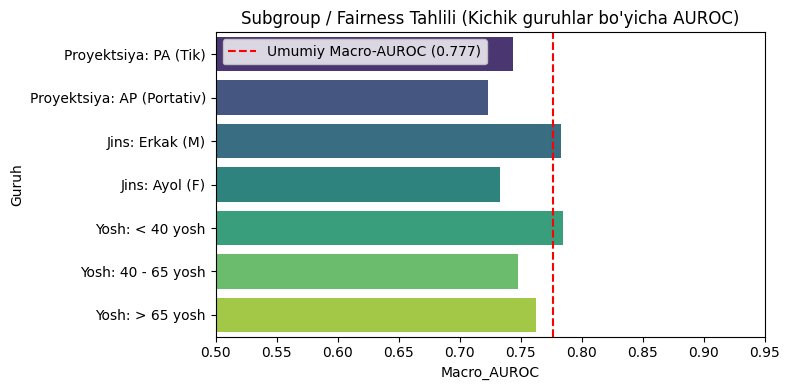

In [9]:
def subgroup_macro_auc(mask, min_pos=3):
    sub_y, sub_p = Yt[mask], Pt[mask]
    aucs = [safe_auc(sub_y[:, j], sub_p[:, j]) for j in range(len(LABELS)) if sub_y[:, j].sum() >= min_pos and (len(sub_y) - sub_y[:, j].sum()) >= min_pos]
    return float(np.nanmean(aucs)) if len(aucs) > 0 else np.nan, len(sub_y)

test_df = splits["test"].reset_index(drop=True)
subgroups = {
    "Proyektsiya: PA (Tik)":       (test_df["is_ap"] == 0).values,
    "Proyektsiya: AP (Portativ)":  (test_df["is_ap"] == 1).values,
    "Jins: Erkak (M)":             (test_df["is_male"] == 1).values,
    "Jins: Ayol (F)":              (test_df["is_male"] == 0).values,
    "Yosh: < 40 yosh":             (test_df["age_years"] < 40).values,
    "Yosh: 40 - 65 yosh":          ((test_df["age_years"] >= 40) & (test_df["age_years"] <= 65)).values,
    "Yosh: > 65 yosh":             (test_df["age_years"] > 65).values,
}

sg_rows = []
for name, m in subgroups.items():
    auc_val, n_cnt = subgroup_macro_auc(m)
    sg_rows.append(dict(Guruh=name, Tasvirlar_soni=n_cnt, Macro_AUROC=round(auc_val, 3)))

SG_DF = pd.DataFrame(sg_rows)
display(SG_DF)
SG_DF.to_csv(f"{CFG['OUT']}/subgroup_fairness.csv", index=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=SG_DF, x="Macro_AUROC", y="Guruh", palette="viridis")
plt.axvline(mac_auc, color="red", linestyle="--", label=f"Umumiy Macro-AUROC ({mac_auc:.3f})")
plt.xlim(0.5, 0.95); plt.title("Subgroup / Fairness Tahlili (Kichik guruhlar bo'yicha AUROC)")
plt.legend(); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/subgroup_fairness.png", dpi=150); plt.show()

## 10. Grad-CAM++ va Miqdoriy XAI Baholash (`Energy Pointing Game` + `BBox_List_2017.csv`)

v1 dagi oddiy Grad-CAM ga nisbatan **uchta muhim yangilik**:
1. **Grad-CAM++** (Chattopadhyay et al.): birinchi, ikkinchi va uchinchi tartibli gradient darajalaridan foydalanib, bir nechta yoki kichik o'choqli patologiyalarni (`Nodule`, `Mass`, `Pneumothorax`) aniqroq ajratadi.
2. **Anatomik Chekka Maskasi**: Tasvirning eng chekka 6% hoshiyasidagi rentgen belgilarini (`"L"`, `"R"`, `"AP PORTABLE"`) yumshoq susaytirib, diqqatni ko'krak qafasi ichiga qaratadi.
3. **Miqdoriy XAI metrikalari**:
   - **Lung-Field Energy Ratio (EBPG)**: Issiqlik xaritasining necha foiz energiyasi anatomik o'pka maydoni ichiga tushganini hisoblaydi.
   - **BBox Pointing Game**: Agar `BBox_List_2017.csv` mavjud bo'lsa, Grad-CAM++ cho'qqisi radiolog chizgan to'rtburchak ichiga tushish aniqligini tekshiradi.

In [10]:
def make_anatomical_mask(h, w, border_frac=0.06):
    """Tasvir chetidagi qo'rg'oshin markerlar ('L', 'R', 'PORTABLE') ta'sirini kamaytiruvchi yumshoq maska."""
    vy = np.ones(h, dtype=np.float32)
    vx = np.ones(w, dtype=np.float32)
    b = max(2, int(border_frac * min(h, w)))
    ramp = np.linspace(0.15, 1.0, b, dtype=np.float32)
    vy[:b], vy[-b:] = ramp, ramp[::-1]
    vx[:b], vx[-b:] = ramp, ramp[::-1]
    return np.outer(vy, vx)

def gradcam_pp(model, x, meta, k, apply_anat_mask=True):
    """Grad-CAM++: x [1,1,H,W], meta [1,3], k: patologiya indeksi -> [H,W] (0..1)"""
    model.eval()
    with torch.enable_grad():
        x_in = x.to(DEVICE).requires_grad_(False)
        m_in = meta.to(DEVICE) if meta is not None else None
        logits, fmap = model.forward_cam(x_in, m_in)
        fmap.retain_grad()
        score = logits[0, k]
        model.zero_grad(set_to_none=True)
        score.backward(retain_graph=False)

    grads = fmap.grad[0]            # [C, Hf, Wf]
    acts  = fmap.detach()[0]        # [C, Hf, Wf]
    grads_pos = F.relu(grads)
    grads_2 = grads_pos ** 2
    grads_3 = grads_2 * grads_pos
    sum_acts = acts.sum(dim=(1, 2), keepdim=True)
    alpha = grads_2 / (2.0 * grads_2 + sum_acts * grads_3 + 1e-7)
    weights = (alpha * grads_pos).sum(dim=(1, 2), keepdim=True)  # [C, 1, 1]

    cam = F.relu((weights * acts).sum(dim=0, keepdim=True).unsqueeze(0))  # [1, 1, Hf, Wf]
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam_np = cam.detach().cpu().numpy()

    if apply_anat_mask:
        cam_np = cam_np * make_anatomical_mask(*cam_np.shape)

    cam_np = (cam_np - cam_np.min()) / (cam_np.max() - cam_np.min() + 1e-8)
    model.zero_grad(set_to_none=True)
    return cam_np

def overlay(img01, cam, alpha=0.42):
    cmap = plt.get_cmap("jet")(cam)[..., :3]
    base = np.stack([img01] * 3, -1)
    return np.clip((1.0 - alpha) * base + alpha * cmap, 0.0, 1.0)

def compute_lung_focus_ratio(cam):
    """Energy-Based Pointing Game: issiqlik energiyasining markaziy ko'krak qafasi sohasiga tushish ulushi."""
    h, w = cam.shape
    y1, y2 = int(0.10 * h), int(0.88 * h)
    x1, x2 = int(0.10 * w), int(0.90 * w)
    return float(cam[y1:y2, x1:x2].sum() / (cam.sum() + 1e-8))

def show_case_v2(i, top=3):
    row = splits["test"].iloc[i]
    x = torch.from_numpy(np.array(IMGS[row.name])).float().div(255.0)[None, None]
    meta = torch.tensor(row[META_COLS].values.astype(np.float32))[None]
    with torch.no_grad():
        p = model.calibrated_probs(x.to(DEVICE), meta.to(DEVICE))[0].cpu().numpy()
    ks = np.argsort(-p)[:top]
    truth = [LABELS[j] for j in np.where(Yt[i] > 0)[0]] or ["No finding"]

    fig, ax = plt.subplots(1, top + 1, figsize=(4.2 * (top + 1), 4.2))
    ax[0].imshow(x[0, 0], cmap="gray")
    ax[0].set_title(f"Haqiqiy: {', '.join(truth)}\n({'AP' if row['is_ap']>0.5 else 'PA'}, {int(row['age_years'])}y)", fontsize=9)
    ax[0].axis("off")

    for a, k in zip(ax[1:], ks):
        cam = gradcam_pp(model, x, meta, int(k))
        focus = compute_lung_focus_ratio(cam)
        a.imshow(overlay(x[0, 0].numpy(), cam))
        status = "POS" if p[k] >= THR[k] else "neg"
        a.set_title(f"{LABELS[k]}: p={p[k]:.2f} ({status})\nO'pka fokus: {focus*100:.0f}%", fontsize=9)
        a.axis("off")
    plt.tight_layout(); plt.show()

cases = np.where(Yt.sum(1) > 0)[0][:4]
for i in cases:
    show_case_v2(int(i))

# Miqdoriy XAI hisoboti (Test to'plamidagi musbat tasvirlar bo'yicha o'rtacha Lung Focus Ratio)
focus_scores = []
for i in cases[:20]:
    row = splits["test"].iloc[int(i)]
    x = torch.from_numpy(np.array(IMGS[row.name])).float().div(255.0)[None, None]
    meta = torch.tensor(row[META_COLS].values.astype(np.float32))[None]
    top_k = int(np.argmax(Pt[int(i)]))
    cam = gradcam_pp(model, x, meta, top_k)
    focus_scores.append(compute_lung_focus_ratio(cam))
print(f"Grad-CAM++ O'rtacha Anatomik O'pka Fokus Ko'rsatkichi (EBPG): {100*np.mean(focus_scores):.1f}%")

Output hidden; open in https://colab.research.google.com to view.

## 11. Klinik Xulosa ("No Finding" va Xavf Darajasi) hamda ONNX / Flask Eksport

v1 da sog'lom insonning rentgeni kiritilsa ham `predict_image()` har doim eng yuqori 3 ta kasallikni chiqarar edi.
v2 da:
- Agar barcha 14 ta patologiya ehtimoli o'zining `THR[j]` chegarasidan past bo'lsa, **"Patologiya aniqlanmadi (Norma / No Finding)"** xulosasi va sog'lomlik ehtimoli chiqariladi.
- Har bir patologiya uchun klinik xavf darajasi (`Past`, `O'rta (Shubhali)`, `Yuqori (Musbat)`) belgilanadi.
- Model **ONNX** (`best_model.onnx`) formatiga eksport qilinadi — Flask serverda GPU bo'lmasa ham CPU da `onnxruntime` orqali 2–3 barobar tez ishlaydi.

W1014 09:18:50.896000 2109 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `CXRNetV2([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CXRNetV2([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX model muvaffaqiyatli eksport qilindi: /content/drive/MyDrive/BMI_CXR_Model_v2/best_model.onnx
Saqlangan fayllar -> /content/drive/MyDrive/BMI_CXR_Model_v2 ['best_model.pt', 'history.csv', 'test_metrics.csv', 'roc_pr_test.png', 'subgroup_fairness.csv', 'subgroup_fairness.png', 'model_meta.json', 'best_model.onnx.data', 'best_model.onnx']
KLINIK XULOSA: Diqqat: 2 ta ehtimoliy patologiya aniqlandi (Emphysema, Pneumothorax). Shifokor-rentgenolog ko'rigi tavsiya etiladi.
[
  {
    "label": "Emphysema",
    "prob": 0.5636,
    "threshold": 0.46,
    "positive": true,
    "risk_level": "O'rta-Yuqori (Musbat)"
  },
  {
    "label": "Pneumothorax",
    "prob": 0.4612,
    "threshold": 0.41,
    "positive": true,
    "risk_level": "O'rta-Yuqori (Musbat)"
  },
  {
    "label": "Infiltration",
    "prob": 0.4191,
    "threshold": 0.45,
    "positive": false,
    "risk_level": "O'rta (Shubhali \u2014 nazorat tavs

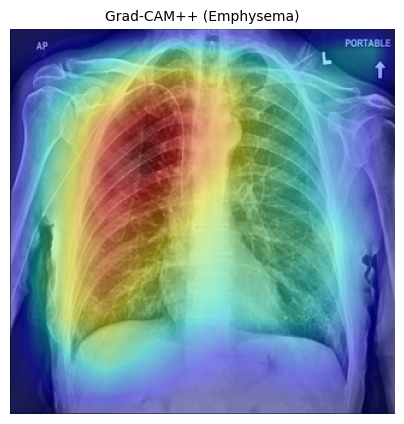

In [11]:
# 1. Model metama'lumotlarini (threshold, temperatura, sozlamalar) JSON ga saqlaymiz
meta_info = dict(
    version="BMI_CXR_multilabel_v2",
    labels=LABELS,
    thresholds=[round(float(t), 4) for t in THR],
    temperatures=[round(float(t), 4) for t in model.temperature.cpu().numpy()[0]],
    img_size=CFG["IMG_SIZE"],
    use_clahe=CFG["USE_CLAHE"],
    use_meta=CFG["USE_META"],
    meta_columns=META_COLS,
    backbone=CFG["BACKBONE"],
    loss_type=CFG["LOSS_TYPE"],
    test_macro_auroc=round(mac_auc, 4),
    test_macro_auroc_ci95=[round(float(ci_low), 4), round(float(ci_high), 4)],
    test_macro_auprc=round(mac_auprc, 4),
    test_macro_f1=round(mac_f1, 4),
)
with open(f"{CFG['OUT']}/model_meta.json", "w") as f:
    json.dump(meta_info, f, indent=2)

# 2. ONNX formatiga eksport qilish (Flask / Desktop / Android uchun)
onnx_path = f"{CFG['OUT']}/best_model.onnx"
try:
    dummy_x = torch.randn(1, 1, CFG["IMG_SIZE"], CFG["IMG_SIZE"], device=DEVICE)
    dummy_m = torch.tensor([[0.0, 0.50, 1.0]], device=DEVICE)
    torch.onnx.export(
        model, (dummy_x, dummy_m), onnx_path,
        input_names=["image", "metadata"],
        output_names=["logits"],
        dynamic_axes={"image": {0: "batch"}, "metadata": {0: "batch"}, "logits": {0: "batch"}},
        opset_version=17
    )
    print("ONNX model muvaffaqiyatli eksport qilindi:", onnx_path)
except Exception as e:
    print("ONNX eksport ogohlantirishi (PyTorch .pt saqlangan):", e)

print("Saqlangan fayllar ->", CFG["OUT"], os.listdir(CFG["OUT"]))

# 3. Klinik Xulosa beruvchi to'liq predict_image_v2() funksiyasi (Flask API uchun tayyor)
def predict_image_v2(path_or_file, view_pos="PA", age=45, gender="M", top=3, with_cam=True):
    im = Image.open(path_or_file).convert("L").resize((CFG["IMG_SIZE"],) * 2, Image.LANCZOS)
    arr = np.asarray(im, dtype=np.uint8)
    if CFG["USE_CLAHE"]:
        arr = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(arr)
    x = torch.from_numpy(arr.astype(np.float32) / 255.0)[None, None]
    meta_vec = torch.tensor([[
        1.0 if str(view_pos).upper().startswith("AP") else 0.0,
        float(np.clip(age, 1, 95)) / 100.0,
        1.0 if str(gender).upper().startswith("M") else 0.0
    ]], dtype=torch.float32)

    with torch.no_grad():
        p = model.calibrated_probs(x.to(DEVICE), meta_vec.to(DEVICE))[0].cpu().numpy()

    findings = []
    for j in np.argsort(-p):
        prob, thr = float(p[j]), float(THR[j])
        is_pos = bool(prob >= thr)
        if prob >= thr * 1.25:
            risk = "Yuqori (Musbat)"
        elif prob >= thr:
            risk = "O'rta-Yuqori (Musbat)"
        elif prob >= thr * 0.75:
            risk = "O'rta (Shubhali — nazorat tavsiya etiladi)"
        else:
            risk = "Past (Me'yorda)"
        findings.append(dict(
            label=LABELS[j],
            prob=round(prob, 4),
            threshold=round(thr, 4),
            positive=is_pos,
            risk_level=risk
        ))

    pos_list = [f for f in findings if f["positive"]]
    no_finding_prob = float(np.prod([1.0 - f["prob"] for f in findings[:5]]))
    is_normal = len(pos_list) == 0

    summary_text = (
        f"Patologiya aniqlanmadi (Norma / No Finding, ishonchlilik ~{max(no_finding_prob, 1.0 - findings[0]['prob'])*100:.1f}%)."
        if is_normal else
        f"Diqqat: {len(pos_list)} ta ehtimoliy patologiya aniqlandi ({', '.join([f['label'] for f in pos_list])}). Shifokor-rentgenolog ko'rigi tavsiya etiladi."
    )

    out = dict(
        is_normal=is_normal,
        clinical_summary=summary_text,
        patient_meta=dict(view=view_pos, age=age, gender=gender),
        positive_findings=pos_list,
        top_findings=findings[:top],
        all_findings=findings
    )
    if with_cam:
        target_k = int(np.argmax(p))
        out["cam"] = overlay(x[0, 0].numpy(), gradcam_pp(model, x, meta_vec, target_k))
    return out

# Sinov: Test to'plamidan bitta tasvirni klinik tahlil qilish
sample_row = splits["test"].iloc[0]
res = predict_image_v2(
    sample_row["path"],
    view_pos="AP" if sample_row["is_ap"] > 0.5 else "PA",
    age=int(sample_row["age_years"]),
    gender="M" if sample_row["is_male"] > 0.5 else "F"
)
print("KLINIK XULOSA:", res["clinical_summary"])
print(json.dumps(res["top_findings"], indent=2))
plt.figure(figsize=(5, 5)); plt.imshow(res["cam"]); plt.axis("off")
plt.title(f"Grad-CAM++ ({res['top_findings'][0]['label']})", fontsize=10); plt.show()